### Checkpoint 1

Implement your algorithm to process and annotate the traces of the 20 unipolar electrogram signals, identifying focal activity based on activation patterns and signal morphology.

The algorithm must return the following outputs:

1. **Activation Annotations**: for each of the 20 signals, generate a list of activation times. These activation times correspond to the local minima of the first derivative of the signal, indicating the moments of depolarization at each electrode.
2. **Focal proximity**: assign a score of 1 to the sensor closest to the focal activity and 0 to all others. If the focal activity is within two sensors (up to a specified tolerance), assign 0.5 to each of the two sensors.
This output should be guided by signal morphology: focal activity is expected to correspond to a QS morphology (i.e., a single dominant negative deflection).

Provide your algorithm's implementation in this notebook to annotate the traces of the 20 unipolar signals and identify focal activity based on activation patterns and waveform morphology.



In [140]:
#Imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema

In [141]:
# load data
signals = np.load('checkpoint1dataset.npy')

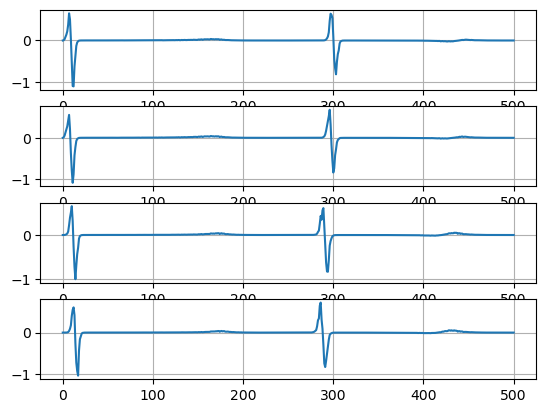

In [150]:
# select event to be display
ind_event = 4

# select a spline (options: 0,1,2,3,4)
ind_spline = 2

# plot signals

plt.figure(1+ind_spline)
countEL = 1
for indS in np.arange(ind_spline*4,(ind_spline+1)*4,1):
    plt.subplot(4,1,countEL)
            
    plt.plot(signals[ind_event,indS,:])
    plt.grid(True)

    countEL = countEL + 1

plt.show()

signals_event = signals[ind_event,:,:]

In [143]:
def GroupSolutionCP1(signals_event):
    n_sensors = signals_event.shape[0]
    timings = []
    
    min_dist = 100 
    time_tol = 4
    
    act_times = [[], []] 
    qs_flags = [[], []]

    for i in range(n_sensors):
        ds = np.diff(signals_event[i, :])
        min_indices = argrelextrema(ds, np.less)[0]
        
        selected = []
        qs_status = [False, False]
        
        if len(min_indices) > 0:
            depths = ds[min_indices]
            sorted_args = np.argsort(depths)
            candidates = min_indices[sorted_args]
            
            for idx in candidates:
                if len(selected) == 0:
                    selected.append(idx)
                elif len(selected) == 1:
                    if abs(idx - selected[0]) >= min_dist:
                        selected.append(idx)
                        break
            
            selected.sort()
            
            for j, val in enumerate(selected):
                window_start = max(0, val - 30)
                window_end = min(signals_event.shape[1], val + 30)
                baseline = np.mean(signals_event[i, window_start : window_start + 5])
                max_pos = np.max(signals_event[i, window_start : val]) - baseline
                max_neg = np.min(signals_event[i, val : window_end]) - baseline
                
                if max_pos < 0.1 * abs(max_neg):
                    qs_status[j] = True

        row_time = [None, None]
        for j in range(len(selected)):
            row_time[j] = int(selected[j])
        
        row_final = [t if t is not None else np.nan for t in row_time]
        timings.append(row_final)

        for j in range(2):
            t_val = row_final[j] if not np.isnan(row_final[j]) else np.inf
            act_times[j].append(t_val)
            qs_flags[j].append(qs_status[j])

    #Calcolo LS
    LS_array = np.zeros((n_sensors, 2))

    for j in range(2):
        times = np.array(act_times[j])
        flags = np.array(qs_flags[j])
        
        if np.any(np.isfinite(times)):
            min_t = np.min(times)
            focus_idxs = [idx for idx, t in enumerate(times) if t <= min_t + time_tol]
            qs_candidates = [idx for idx in focus_idxs if flags[idx]]
            
            if qs_candidates:
                qs_candidates.sort(key=lambda x: times[x])
                
                if len(qs_candidates) == 1:
                    LS_array[qs_candidates[0], j] = 1.0
                
                else:
                    t0 = times[qs_candidates[0]]
                    t1 = times[qs_candidates[1]]
                                        
                    if abs(t1 - t0) <= time_tol:
                        LS_array[qs_candidates[0], j] = 0.5
                        LS_array[qs_candidates[1], j] = 0.5
                    else:
                        LS_array[qs_candidates[0], j] = 1.0

    LS = LS_array.tolist()
    
    return timings, LS

In [144]:
# test it

timings_event, LS_event = GroupSolutionCP1(signals_event)

print(timings_event)
print("LS_event", LS_event)

[[32, 299], [30, 296], [24, 289], [23, 286], [16, 305], [16, 302], [16, 294], [16, 291], [9, 300], [8, 297], [11, 290], [13, 289], [28, 286], [26, 283], [22, 280], [22, 280], [37, 283], [35, 280], [27, 277], [25, 280]]
LS_event [[0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0]]
